In [16]:
import pandas as pd
df=pd.read_csv("movie_ratings.csv")
df.head()

,name,year,movie_rated,run_length,genres,release_date,rating,num_raters,num_reviews
0,Inception,2010,PG-13,2h 28min,Action; Adventure; Sci-Fi;,16 July 2010 (USA),8.8,1981675,3820
1,The Lord of the Rings: The Fellowship of the Ring,2001,PG-13,2h 58min,Action; Adventure; Drama;,19 December 2001 (USA),8.8,1609165,5365
2,The Lord of the Rings: The Return of the King,2003,PG-13,3h 21min,Adventure; Drama; Fantasy;,17 December 2003 (USA),8.9,1593859,3681
3,The Dark Knight Rises,2012,PG-13,2h 44min,Action; Adventure;,20 July 2012 (USA),8.4,1470329,2979
4,The Lord of the Rings: The Two Towers,2002,PG-13,2h 59min,Adventure; Drama; Fantasy;,18 December 2002 (USA),8.7,1440188,2559


In [17]:
df.isnull().sum()

name            0
year            0
movie_rated     0
run_length      0
genres          0
release_date    0
rating          0
num_raters      0
num_reviews     0
dtype: int64

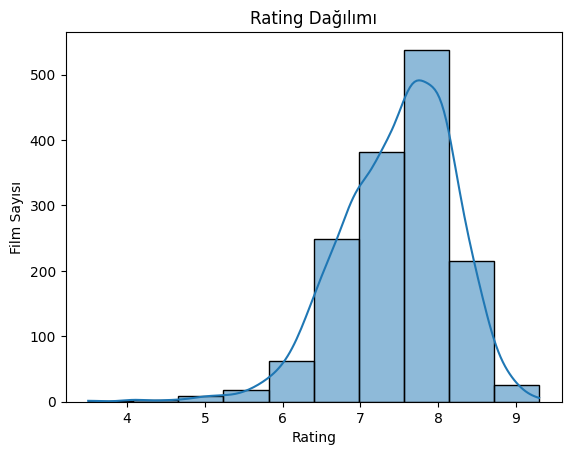

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ortalama rating'lerin dağılımı
sns.histplot(df['rating'], bins=10, kde=True)
plt.title("Rating Dağılımı")
plt.xlabel("Rating")
plt.ylabel("Film Sayısı")
plt.show()

In [ ]:
# Ratingi en yüksek 5 film
top_5_movies = df.sort_values(by='rating', ascending=False).head(5)
print(top_5_movies[['name', 'rating']])


                         name  rating
500  The Shawshank Redemption     9.3
402             The Godfather     9.2
507             The Godfather     9.2
408    The Godfather: Part II     9.0
501           The Dark Knight     9.0


In [31]:
# Rating sayısıyla ortalama rating arasında korelasyon
correlation = df['rating'].corr(df['num_raters'])
print("Rating ile Oy Sayısı Arasındaki Korelasyon:", correlation)

Rating ile Oy Sayısı Arasındaki Korelasyon: 0.5574221090292995


In [32]:
# Belirli bir yıldan sonra çıkan filmler, daha yüksek puan mı alıyor?

# Sınır olarak 2010 alalım. Buna göre  Önce iki ayrı grubu ayıralım: 
before_2010 = df[df['year'] < 2010]
after_2010 = df[df['year'] >= 2010]

# Ortalama ratingleri hesapla:
mean_before = before_2010['rating'].mean()
mean_after = after_2010['rating'].mean()

print("2010 öncesi ortalama rating:", round(mean_before, 2))
print("2010 sonrası ortalama rating:", round(mean_after, 2))


2010 öncesi ortalama rating: 7.56
2010 sonrası ortalama rating: 7.34


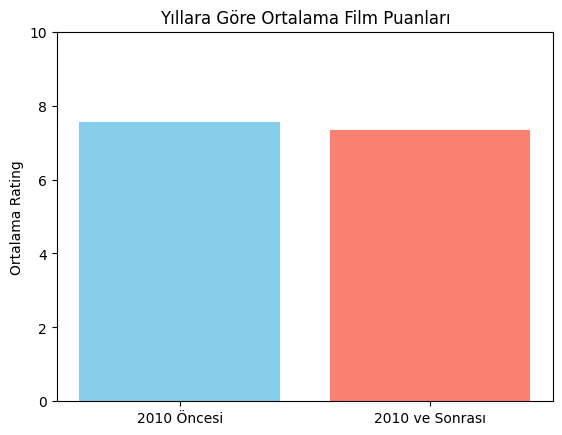

In [33]:
import matplotlib.pyplot as plt

ratings_data = [mean_before, mean_after]
labels = ['2010 Öncesi', '2010 ve Sonrası']

plt.bar(labels, ratings_data, color=['skyblue', 'salmon'])
plt.ylabel("Ortalama Rating")
plt.title("Yıllara Göre Ortalama Film Puanları")
plt.ylim(0, 10)
plt.show()


In [ ]:
# İki grup arasında istatistiksel olarak anlamlı fark var mı diye t-test yapabilirsin:
from scipy.stats import ttest_ind

t_stat, p_val = ttest_ind(before_2010['rating'].dropna(), after_2010['rating'].dropna())
print("T-istatistiği:", t_stat)
print("P-değeri:", p_val)

# p < 0.05 ise → iki grup arasında anlamlı fark var.
# p ≥ 0.05 ise → fark tesadüfi olabilir.


T-istatistiği: 5.7564648158223495
P-değeri: 1.0401245122788196e-08


In [ ]:
# En çok oy alan 10 film
top_10_raters = df.sort_values(by='num_raters', ascending=False).head(10)
print(top_10_raters[['name','num_raters']])

                          name  num_raters
500   The Shawshank Redemption     2258845
501            The Dark Knight     2224522
400            The Dark Knight     2224522
1200                 Inception     1981688
0                    Inception     1981675
502                 Fight Club     1794454
401               Pulp Fiction     1767445
503               Pulp Fiction     1767445
1100              Forrest Gump     1741481
504               Forrest Gump     1741097


In [37]:
# En az puan alan ama çok oy alan filmler
x = df[df['num_raters'] > 1000].sort_values(by='rating').head()
print(x[['name','rating', 'num_raters']])

                                name  rating  num_raters
992                      Spice World     3.5       32688
1140            Fifty Shades of Grey     4.1      291846
1391            Fifty Shades of Grey     4.1      291813
1473  In the Land of Blood and Honey     4.5       33167
676      The Twilight Saga: New Moon     4.7      258910


In [39]:
# Rating ortalaması kaç? Standart sapması nedir?
ortalama = df['rating'].mean()
print('Ortalama:' , ortalama)
standartSapma = df['rating'].std()
print('Standart Sapma', standartSapma)

Ortalama: 7.477600000000001
Standart Sapma 0.7250347280679754


<Axes: xlabel='year'>

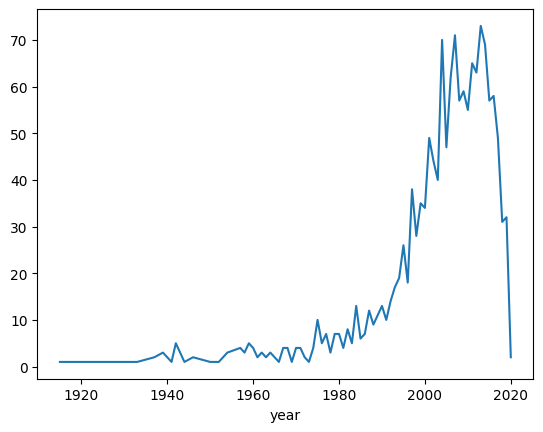

In [43]:
# Hangi yıllarda daha çok film çıkmış?
df['year'].value_counts().sort_index().plot()

<Axes: xlabel='year'>

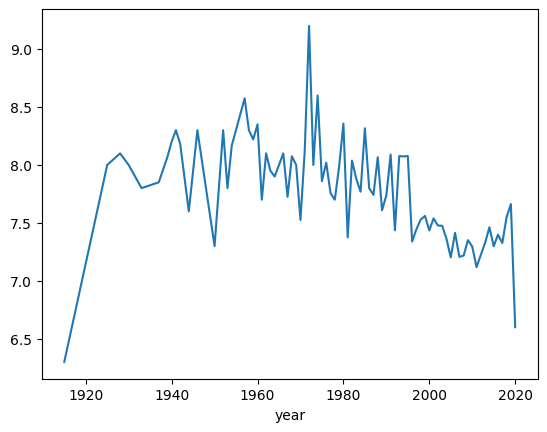

In [44]:
# Hangi yılın filmleri ortalama olarak daha yüksek puan almış?
df.groupby('year')['rating'].mean().plot()

In [46]:
# Oy sayısıyla rating arasında korelasyon nedir?
korelasyon = df['rating'].corr(df['num_raters'])
print(korelasyon)

0.5574221090292995


In [49]:
# Tür (genre) bazında ortalama puan farkı var mı?
df.groupby('genres')['rating'].mean()

genres
Action; Adventure;                8.300000
Action; Adventure; Biography;     7.100000
Action; Adventure; Comedy;        7.750000
Action; Adventure; Crime;         7.300000
Action; Adventure; Drama;         8.180000
                                    ...   
Mystery; Thriller;                7.811111
Romance;                          7.511111
Sci-Fi;                           7.800000
Sci-Fi; Thriller;                 7.400000
Thriller; War;                    7.200000
Name: rating, Length: 181, dtype: float64

In [57]:
# Yıllara göre en popüler (en çok oylanan) film hangisiydi?
df.groupby('year')['num_raters'].idxmax()

year
1915    1492
1925     788
1928     798
1930    1444
1933    1446
        ... 
2016     305
2017    1235
2018    1215
2019    1310
2020     985
Name: num_raters, Length: 80, dtype: int64

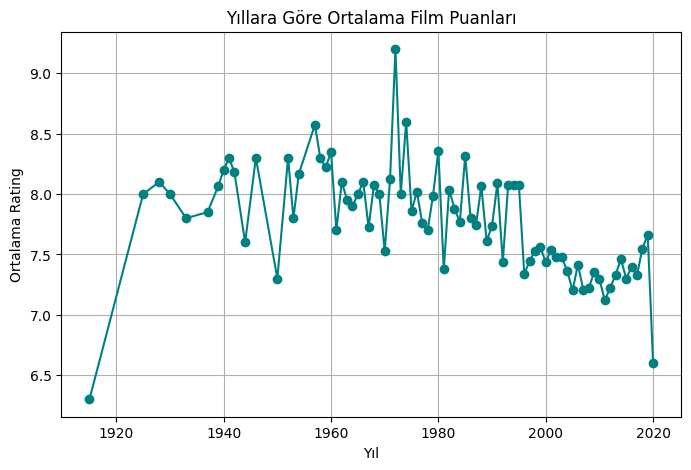

In [ ]:
# “Yıllara Göre Film Kalitesi Düşüyor mu?”
# Her yıl çıkan filmlerin ortalama puanını çizerek film kalitesinin zamanla nasıl değiştiğini analiz etmek

avg_ratings_by_year = df.groupby('year')['rating'].mean()

plt.figure(figsize=(8, 5))
avg_ratings_by_year.plot(marker='o', color='teal')
plt.title("Yıllara Göre Ortalama Film Puanları")
plt.xlabel("Yıl")
plt.ylabel("Ortalama Rating")
plt.grid(True)
plt.show()


In [ ]:
# “En Adaletsiz Filmler: Çok Oy Aldı Ama Düşük Puan”
# Çok sayıda kişi tarafından oy almasına rağmen düşük puan alan filmleri bularak “halkın tepkisini” anlamak.

popular_bad = df[df['num_raters'] > 10000].sort_values(by='rating').head(10)
print(popular_bad[['name', 'year', 'rating', 'num_raters']])

                                           name  year  rating  num_raters
992                                 Spice World  1997     3.5       32688
1140                       Fifty Shades of Grey  2015     4.1      291846
1391                       Fifty Shades of Grey  2015     4.1      291813
1473             In the Land of Blood and Honey  2011     4.5       33167
676                 The Twilight Saga: New Moon  2009     4.7      258910
695   The Twilight Saga: Breaking Dawn - Part 1  2011     4.9      217803
1092                              The Happening  2008     5.0      192408
991                              Happy New Year  2014     5.0       33033
692                  The Twilight Saga: Eclipse  2010     5.0      221496
637                                    Twilight  2008     5.2      413276


In [75]:
# “İzlenmesi Gereken Gizli Cevherler”
# Az kişinin oy verdiği ama yüksek puan almış filmleri bulmak → “hidden gem” tarzı öneriler.

hidden_gems = df[(df['num_raters'] < 30000) & (df['rating'] > 7)].sort_values(by='rating', ascending=False)
print(hidden_gems[['name', 'year', 'rating', 'num_raters']].head(10))


                    name  year  rating  num_raters
1483  To Be or Not to Be  1942     8.2       26579
1487    The Caine Mutiny  1954     7.7       23779
1481     Duck You Sucker  1971     7.6       28849
1485          Gettysburg  1993     7.6       25505
1484            Lifeboat  1944     7.6       25656
1490       Bloody Sunday  2002     7.6       22908
1480          Stalingrad  1993     7.5       29900
1486       Cross of Iron  1977     7.5       24560
1493          Little Boy  2015     7.4       21808
1491            Saboteur  1942     7.2       22497


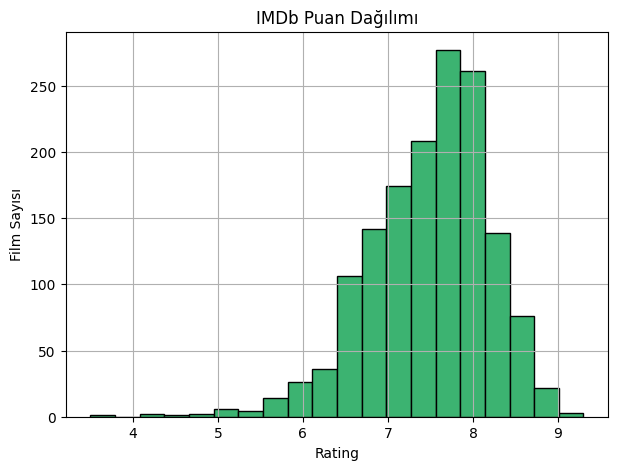

In [77]:
# “IMDb Rating Dağılımı Analizi”
# Rating skorlarının genel dağılımı nasıl? Normal dağılım mı var? Aykırı değer çok mu?

plt.figure(figsize=(7,5))
plt.hist(df['rating'], bins=20, color='mediumseagreen', edgecolor='black')
plt.title("IMDb Puan Dağılımı")
plt.xlabel("Rating")
plt.ylabel("Film Sayısı")
plt.grid(True)
plt.show()
